In [ ]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT)


In [1]:
# Cell 1 — imports + both coherence functions (self-contained)
import scqubits as scq, numpy as np, pandas as pd
import matplotlib.pyplot as plt, os, json, datetime
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True)
scq.settings.T1_DEFAULT_WARNING = False

def safe(fn, **kw):
    try: return fn(**kw)
    except Exception: return np.inf

def transmon_T2(EJ, EC, ng=0.0, ncut=30, Q_cap=1e6, A_ng=1e-4, A_cc=1e-7):
    tm = scq.Transmon(EJ=EJ, EC=EC, ng=ng, ncut=ncut)
    T1  = safe(tm.t1_capacitive, i=1, j=0, Q_cap=Q_cap)
    Tng = safe(tm.tphi_1_over_f_ng, A_noise=A_ng, i=0, j=1)
    Tcc = safe(tm.tphi_1_over_f_cc, A_noise=A_cc, i=0, j=1)
    return (1/(1/(2*T1)+1/Tng+1/Tcc))*1e-3   # us

def fluxonium_T2(EJ=8.9, EC=2.5, EL=0.5, flux=0.5, cutoff=110,
                 Q_cap=1e6, A_flux=1e-6, A_cc=1e-7):
    fx = scq.Fluxonium(EJ=EJ, EC=EC, EL=EL, flux=flux, cutoff=cutoff)
    T1 = 1/(1/safe(fx.t1_capacitive, i=1, j=0, Q_cap=Q_cap)
            + 1/safe(fx.t1_quasiparticle_tunneling, i=1, j=0))
    Tf  = safe(fx.tphi_1_over_f_flux, A_noise=A_flux, i=0, j=1)
    Tcc = safe(fx.tphi_1_over_f_cc, A_noise=A_cc, i=0, j=1)
    return (1/(1/(2*T1)+1/Tf+1/Tcc))*1e-3    # us

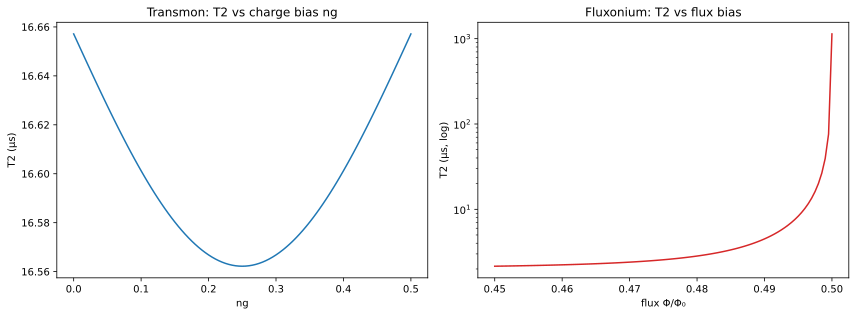

Transmon  T2 range across ng: 16.6 – 16.7 µs (factor 1.01)
Fluxonium T2 range across flux 0.45–0.50: 2.2 – 1136.9 µs (factor 528)


In [2]:
# Cell 2 — sensitivity to the bias knob, side by side
ng_vals   = np.linspace(0.0, 0.5, 101)      # transmon charge bias (sweet at 0 and 0.5)
flux_vals = np.linspace(0.45, 0.50, 101)    # fluxonium flux bias (sweet at 0.5)

tmon_T2 = [transmon_T2(50, 1.0, ng=n) for n in ng_vals]      # EJ/EC=50, a real transmon
flux_T2 = [fluxonium_T2(flux=f) for f in flux_vals]

fig, ax = plt.subplots(1, 2, figsize=(12,4.5))
ax[0].plot(ng_vals, tmon_T2); ax[0].set_title('Transmon: T2 vs charge bias ng')
ax[0].set_xlabel('ng'); ax[0].set_ylabel('T2 (µs)')
ax[1].semilogy(flux_vals, flux_T2, color='tab:red')
ax[1].set_title('Fluxonium: T2 vs flux bias'); ax[1].set_xlabel('flux Φ/Φ₀'); ax[1].set_ylabel('T2 (µs, log)')
plt.tight_layout(); plt.savefig('figures/q3_bias_sensitivity.png', dpi=150, bbox_inches='tight'); plt.show()

# quantify the contrast
print(f"Transmon  T2 range across ng: {min(tmon_T2):.1f} – {max(tmon_T2):.1f} µs "
      f"(factor {max(tmon_T2)/min(tmon_T2):.2f})")
print(f"Fluxonium T2 range across flux 0.45–0.50: {min(flux_T2):.1f} – {max(flux_T2):.1f} µs "
      f"(factor {max(flux_T2)/min(flux_T2):.0f})")

In [3]:
# Cell 3 — Monte Carlo over literature noise ranges
rng = np.random.default_rng(0)
N = 60
ratios, tmon_best, flux_best = [], [], []
for _ in range(N):
    # sample each amplitude log-uniformly within a literature-plausible band
    Q     = 10**rng.uniform(5, 7)      # dielectric quality factor 1e5–1e7
    A_fl  = 10**rng.uniform(-6, -5)    # flux noise 1e-6–1e-5
    A_c   = 10**rng.uniform(-7, -6)    # critical-current noise
    A_n   = 10**rng.uniform(-4, -3)    # charge noise
    t = transmon_T2(50, 1.0, ng=0.25, Q_cap=Q, A_ng=A_n, A_cc=A_c)   # transmon worst-case bias
    f = fluxonium_T2(EJ=15, EL=0.2, flux=0.5, Q_cap=Q, A_flux=A_fl, A_cc=A_c)  # fluxonium best design
    tmon_best.append(t); flux_best.append(f); ratios.append(f/t)

ratios = np.array(ratios)
print(f"Fluxonium/Transmon T2 ratio: median {np.median(ratios):.1f}, "
      f"90% CI [{np.percentile(ratios,5):.1f}, {np.percentile(ratios,95):.1f}]")
print(f"Fraction of samples where fluxonium wins: {(ratios>1).mean()*100:.0f}%")

Fluxonium/Transmon T2 ratio: median 216.2, 90% CI [51.8, 371.1]
Fraction of samples where fluxonium wins: 100%


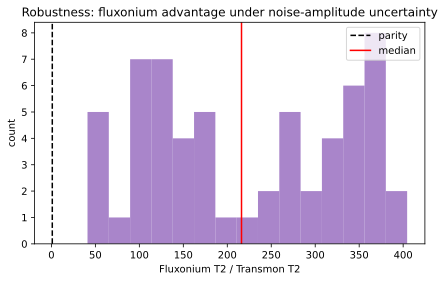

In [4]:
# Cell 4 — visualize the robustness spread
plt.figure(figsize=(7,4))
plt.hist(ratios, bins=15, color='tab:purple', alpha=0.8)
plt.axvline(1, color='k', ls='--', label='parity')
plt.axvline(np.median(ratios), color='red', label='median')
plt.xlabel('Fluxonium T2 / Transmon T2'); plt.ylabel('count')
plt.title('Robustness: fluxonium advantage under noise-amplitude uncertainty')
plt.legend(); plt.savefig('figures/q3_robustness_hist.png', dpi=150, bbox_inches='tight'); plt.show()

Fluxonium T2 scales as (flux detuning)^-0.68 near the sweet spot


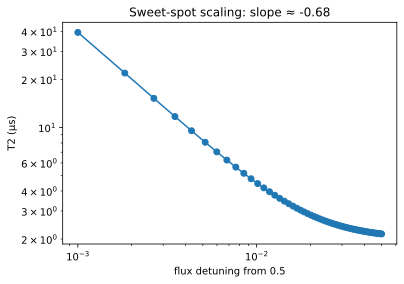

In [5]:
# Cell 5 — how fast does fluxonium coherence fall off the sweet spot?
det = np.linspace(0.001, 0.05, 60)               # detuning from flux=0.5
T2d = np.array([fluxonium_T2(flux=0.5-d) for d in det])
# fit T2 ~ detuning^power on log-log
p = np.polyfit(np.log(det), np.log(T2d), 1)
print(f"Fluxonium T2 scales as (flux detuning)^{p[0]:.2f} near the sweet spot")
plt.figure(figsize=(6,4))
plt.loglog(det, T2d, 'o-'); plt.xlabel('flux detuning from 0.5'); plt.ylabel('T2 (µs)')
plt.title(f'Sweet-spot scaling: slope ≈ {p[0]:.2f}'); 
plt.savefig('figures/fluxonium_scaling.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
# Cell 6 — metadata
json.dump({'date':str(datetime.date.today()),'stage':'Week 4 analysis',
           'monte_carlo_N':60,
           'ranges':{'Q_cap':'1e5-1e7','A_flux':'1e-6-1e-5','A_cc':'1e-7-1e-6','A_ng':'1e-4-1e-3'},
           'figures':['q3_bias_sensitivity.png','q3_robustness_hist.png','fluxonium_scaling.png']},
          open('data/week4_analysis_metadata.json','w'), indent=2)
print('saved')

saved
